In [1]:
import numpy as np
import pandas as pd
import pickle, os
from itertools import product
import matplotlib.pyplot as plt

import jax.numpy as jnp
import jax.random as jr
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_median
from scipy.stats import binned_statistic


In [9]:
# ------------------------------------------------------------------
# 0. Load data (already R<16, wedge-restricted, from the extraction notebook)
# ------------------------------------------------------------------
df = pd.read_parquet("merger_sim_wedge_full(1).parquet")
R   = df["R"].to_numpy()
z   = df["z"].to_numpy()
phi = df["phi"].to_numpy()
tracer     = df["ofe"].to_numpy()
tracer_err = np.full_like(tracer, 1e-4)   # dummy per-star error, sim is noise-free

# ------------------------------------------------------------------
# 1. Segment/wedge setup (inlined, same as before)
# ------------------------------------------------------------------
def wrap_to_2pi(a): return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    da = (b-a) % (2*np.pi); dx = (x-a) % (2*np.pi); return dx < da

def build_segment_setup(phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11):
    ph = wrap_to_2pi(phi_star); phi0 = wrap_to_2pi(phi0)
    hw = np.deg2rad(crowd_halfwidth_deg)
    a = wrap_to_2pi(phi0 - hw); b = wrap_to_2pi(phi0 + hw)
    span = (b-a) % (2*np.pi)
    crowd_bounds = wrap_to_2pi(a + np.linspace(0, span, n_crowd+1))
    segm = {}
    for i in range(n_crowd):
        segm[i+1] = between_ccw(ph, crowd_bounds[i], crowd_bounds[i+1])
    in_crowd = between_ccw(ph, a, b)
    segm[n_crowd+1] = ~in_crowd
    diagnostics = {"n_crowd": n_crowd, "seg_rest_id": n_crowd+1, "seg_plot": list(range(1, n_crowd+1))}
    return segm, crowd_bounds, (a, b), diagnostics

phi0 = np.pi
segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11)
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)

# ------------------------------------------------------------------
# 2. sech2 mixture model + NUTS fit (same machinery as your real pipeline)
# ------------------------------------------------------------------
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    return A1 / jnp.cosh((z - z0) / h1)**2 + A2 / jnp.cosh((z - z0) / h2)**2

def model(z_binc, mean_mg_fe, mean_mg_fe_err):
    A1 = -numpyro.sample("A1_pos", dist.HalfNormal(0.2))
    A2 = -numpyro.sample("A2_pos", dist.HalfNormal(0.2))
    numpyro.deterministic("A1", A1)
    numpyro.deterministic("A2", A2)
    h1 = numpyro.sample("h1", dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.75))
    h2 = h1 + d_h2
    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))
    model_y = mixture_of_sech2(z_binc, A1, A2, h1, h2, z0) + offset
    numpyro.sample("obs", dist.Normal(model_y, mean_mg_fe_err), obs=mean_mg_fe)

def bin_one(z_arr, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    stat1, edges, _ = binned_statistic(z_arr, mgfe / mgfe_err**2, statistic="sum", bins=z_bins)
    stat2, _, _     = binned_statistic(z_arr, 1 / mgfe_err**2,    statistic="sum", bins=z_bins)
    mean_mg_fe = stat1 / stat2
    counts, _, _   = binned_statistic(z_arr, mgfe, statistic="count", bins=z_bins)
    stat_std, _, _ = binned_statistic(z_arr, mgfe, statistic="std", bins=z_bins)
    intrinsic_scatter = stat_std / np.sqrt(np.maximum(counts, 1))
    mean_mg_fe_err = np.sqrt(1 / stat2 + intrinsic_scatter**2)
    z_binc = 0.5 * (edges[:-1] + edges[1:])
    good = np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err) & (counts > 0)
    return z_binc[good], mean_mg_fe[good], mean_mg_fe_err[good], counts[good]

def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key, progress_bar=True):
    kernel = NUTS(model, dense_mass=True, target_accept_prob=0.95, init_strategy=init_to_median(num_samples=20))
    mcmc = MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=progress_bar)
    mcmc.run(key, z_binc=jnp.asarray(z_binc), mean_mg_fe=jnp.asarray(mean_mg_fe), mean_mg_fe_err=jnp.asarray(mean_mg_fe_err))
    return mcmc

def select_annulus_segment_sim(R_arr, z_arr, tracer_arr, tracer_err_arr, seg_mask, Rmin, Rmax,
                                min_bin_count=5, min_bins_for_fit=8, minN_total=15,
                                z_fit_min=-1.5, z_fit_max=1.5):
    m = seg_mask & (R_arr >= Rmin) & (R_arr < Rmax)
    if m.sum() < minN_total:
        return None, None, None, int(m.sum()), False
    z_binc, mean_k, err_k, counts = bin_one(z_arr[m], tracer_arr[m], tracer_err_arr[m])
    in_fit_range = (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    z_binc, mean_k, err_k, counts = z_binc[in_fit_range], mean_k[in_fit_range], err_k[in_fit_range], counts[in_fit_range]
    ok = (counts >= min_bin_count).sum() >= min_bins_for_fit
    return z_binc, mean_k, err_k, int(m.sum()), ok

In [14]:
# ------------------------------------------------------------------
# 3. Grid fit over (R, segment) cells
# ------------------------------------------------------------------
RESULTS_PATH = "merger_sim_z0_chemistry_grid.pkl"
FORCE_RERUN = True

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med, z0_std, per_cell = saved["z0_med"], saved["z0_std"], saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}")
else:
    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    z0_med = np.full((n_R, n_seg), np.nan)
    z0_std = np.full((n_R, n_seg), np.nan)
    per_cell = {}
    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment_sim(
            R, z, tracer, tracer_err, segm[seg_id], Rmin, Rmax)
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            per_cell[(i_R, j_seg)] = {"z_binc": z_binc_k, "mean": mean_k, "err": err_k,
                                       "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()}}
        except Exception as e:
            print(f"  fit failed seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "per_cell": per_cell,
                     "R_edges": R_edges, "SEG_PLOT_heat": SEG_PLOT_heat,
                     "crowd_bounds": np.asarray(crowd_bounds)}, f)
    print(f"saved to {RESULTS_PATH}")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:62: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1 / stat2
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:66: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2 + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:73: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=progress_bar)


  done 10/330
  done 20/330
  done 30/330
  done 40/330
  done 50/330
  done 60/330
  done 70/330
  done 80/330
  done 90/330
  done 100/330
  done 110/330
  done 120/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
  done 310/330
  done 320/330
  done 330/330
saved to merger_sim_z0_chemistry_grid.pkl


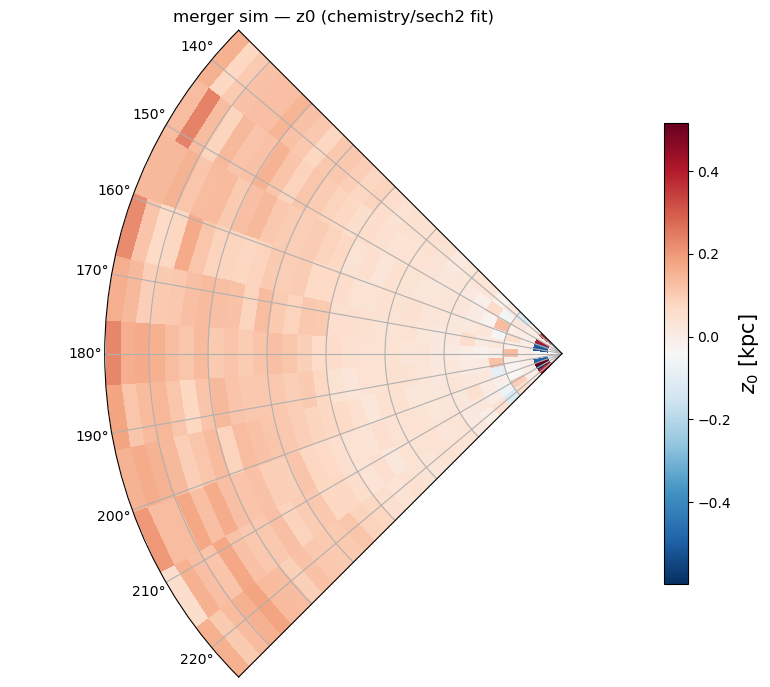

In [15]:
# ------------------------------------------------------------------
# 4. Heatmap
# ------------------------------------------------------------------
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Z0map = np.ma.masked_invalid(z0_med)

fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(1, 1, 1, projection="polar")
pcm = ax.pcolormesh(T_mesh, R_mesh, Z0map, cmap="RdBu_r", shading="flat")
fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$z_0$ [kpc]", fontsize=15)
ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
ax.set_yticklabels([])
plt.title("merger sim — z0 (chemistry/sech2 fit)")
plt.tight_layout()
plt.show()

In [16]:
print("total stars in df:", len(df))
print("finite R,z,phi,tracer:", np.isfinite(R).sum(), np.isfinite(z).sum(), np.isfinite(phi).sum(), np.isfinite(tracer).sum())

for seg_id in SEG_PLOT_heat:
    print(f"segment {seg_id}: {segm[seg_id].sum()} stars total in segment")

print("R range:", np.nanmin(R), np.nanmax(R))
print("z range:", np.nanmin(z), np.nanmax(z))

total stars in df: 9984210
finite R,z,phi,tracer: 9984210 9984210 9984210 9984210
segment 1: 906917 stars total in segment
segment 2: 907967 stars total in segment
segment 3: 907188 stars total in segment
segment 4: 909200 stars total in segment
segment 5: 908953 stars total in segment
segment 6: 907739 stars total in segment
segment 7: 906421 stars total in segment
segment 8: 908103 stars total in segment
segment 9: 907350 stars total in segment
segment 10: 907096 stars total in segment
segment 11: 907276 stars total in segment
R range: 0.00028479247088840967 15.99999851221757
z range: -18.752059008235978 26.05727041628


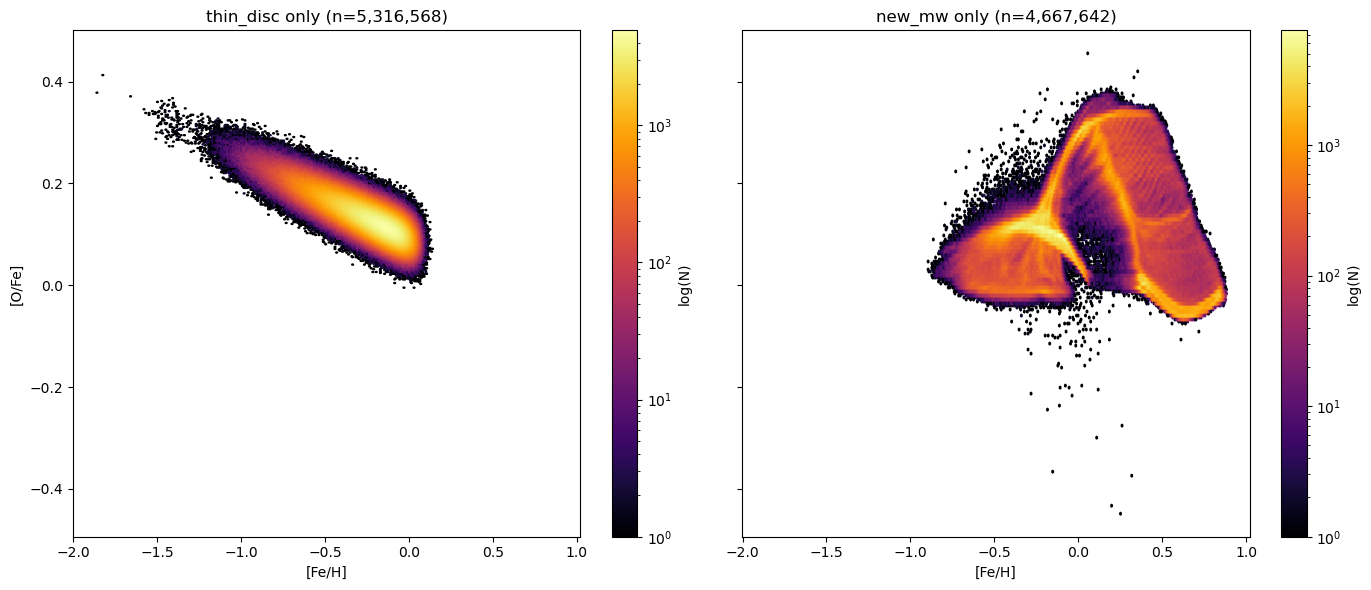

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
mask_thin = df["is_thin_disc"].to_numpy()
mask_newmw = df["is_new_mw"].to_numpy()
for ax, mask, label in [
    (axes[0], mask_thin, "thin_disc only"),
    (axes[1], mask_newmw, "new_mw only"),
]:
    hb = ax.hexbin(df["feh"].to_numpy()[mask], df["ofe"].to_numpy()[mask],
                    gridsize=200, bins="log", mincnt=1, cmap="inferno")
    ax.set_xlabel("[Fe/H]")
    ax.set_title(f"{label} (n={mask.sum():,})")
    fig.colorbar(hb, ax=ax, label="log(N)")

axes[0].set_ylabel("[O/Fe]")
plt.tight_layout()
plt.show()

thin_disc only: 5316568 stars


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:62: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1 / stat2
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:66: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2 + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:73: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=progress_bar)


  done 10/330
  done 20/330
  done 30/330
  done 40/330
  done 50/330
  done 60/330
  done 70/330
  done 80/330
  done 90/330
  done 100/330
  done 110/330
  done 120/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
  done 310/330
  done 320/330
  done 330/330
fits complete: 330 / 330
saved to merger_sim_z0_thindisc_grid.pkl


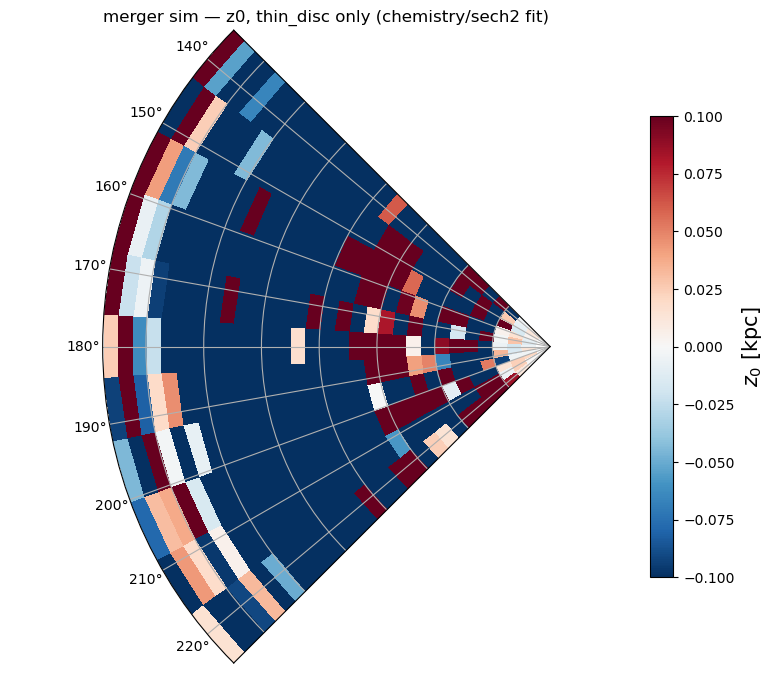

new_mw only: 4667642 stars


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:62: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1 / stat2
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:66: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2 + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:73: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=progress_bar)


  done 10/330
  done 20/330
  done 30/330
  done 40/330
  done 50/330
  done 60/330
  done 70/330
  done 80/330
  done 90/330
  done 100/330
  done 110/330
  done 120/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330


KeyboardInterrupt: 

In [19]:
def run_z0_grid_fit(mask, results_path, force_rerun=False):
    R_sub   = R[mask]
    z_sub   = z[mask]
    tracer_sub     = tracer[mask]
    tracer_err_sub = tracer_err[mask]
    segm_sub = {seg_id: m[mask] for seg_id, m in segm.items()}

    if os.path.exists(results_path) and not force_rerun:
        with open(results_path, "rb") as f:
            saved = pickle.load(f)
        print(f"loaded results from {results_path}")
        return saved["z0_med"], saved["z0_std"], saved["per_cell"]

    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    z0_med = np.full((n_R, n_seg), np.nan)
    z0_std = np.full((n_R, n_seg), np.nan)
    per_cell = {}
    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment_sim(
            R_sub, z_sub, tracer_sub, tracer_err_sub, segm_sub[seg_id], Rmin, Rmax)
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            per_cell[(i_R, j_seg)] = {"z_binc": z_binc_k, "mean": mean_k, "err": err_k,
                                       "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()}}
        except Exception as e:
            print(f"  fit failed seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", sum(np.isfinite(z0_med.ravel())), "/", z0_med.size)
    with open(results_path, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "per_cell": per_cell}, f)
    print(f"saved to {results_path}")
    return z0_med, z0_std, per_cell


def plot_z0_heatmap(z0_med, title):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i-1]:
            theta_edges[i] += 2*np.pi
    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Z0map = np.ma.masked_invalid(z0_med)

    fig = plt.figure(figsize=(8, 7))
    ax = plt.subplot(1, 1, 1, projection="polar")
    pcm = ax.pcolormesh(T_mesh, R_mesh, Z0map, cmap="RdBu_r", vmin=-0.1, vmax=0.1, shading="flat")
    fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$z_0$ [kpc]", fontsize=15)
    ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
    ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
    ax.set_yticklabels([])
    plt.title(title)
    plt.tight_layout()
    plt.show()


# thin disc only
print(f"thin_disc only: {mask_thin.sum()} stars")
z0_med_thin, z0_std_thin, per_cell_thin = run_z0_grid_fit(
    mask_thin, "merger_sim_z0_thindisc_grid.pkl", force_rerun=True)
plot_z0_heatmap(z0_med_thin, "merger sim — z0, thin_disc only (chemistry/sech2 fit)")

# new mw only
print(f"new_mw only: {mask_newmw.sum()} stars")
z0_med_newmw, z0_std_newmw, per_cell_newmw = run_z0_grid_fit(
    mask_newmw, "merger_sim_z0_newmw_grid.pkl", force_rerun=True)
plot_z0_heatmap(z0_med_newmw, "merger sim — z0, new_mw only (chemistry/sech2 fit)")

In [ ]:
# ------------------------------------------------------------------
# Load the new all-population parquet (thin disc + thick disc + halo + new MW)
# ------------------------------------------------------------------
df_all = pd.read_parquet("merger_sim_wedge_allpop.parquet")

R_all   = df_all["R"].to_numpy()
z_all   = df_all["z"].to_numpy()
phi_all = df_all["phi"].to_numpy()
tracer_all     = df_all["ofe"].to_numpy()
tracer_err_all = np.full_like(tracer_all, 1e-4)

print("total stars:", len(df_all))
print("  thin_disc:", df_all["is_thin_disc"].sum())
print("  thick_disc:", df_all["is_thick_disc"].sum())
print("  halo:", df_all["is_halo"].sum())
print("  new_mw:", df_all["is_new_mw"].sum())

# same wedge/segment setup as before (phi0=pi, 45deg halfwidth, 11 segments)
segm_all, crowd_bounds_all, window_edges_all, seg_diag_all = build_segment_setup(
    phi_all, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat_all = list(range(1, seg_diag_all["n_crowd"] + 1))

# ------------------------------------------------------------------
# Grid fit (reuses mixture_of_sech2/model/bin_one/fit_sech2/select_annulus_segment_sim
# already defined earlier in this notebook)
# ------------------------------------------------------------------
def run_z0_grid_fit_all(R_use, z_use, tracer_use, tracer_err_use, segm_use, seg_plot_use,
                         results_path, force_rerun=False):
    if os.path.exists(results_path) and not force_rerun:
        with open(results_path, "rb") as f:
            saved = pickle.load(f)
        print(f"loaded results from {results_path}")
        return saved["z0_med"], saved["z0_std"], saved["per_cell"]

    n_R, n_seg = len(R_edges) - 1, len(seg_plot_use)
    z0_med = np.full((n_R, n_seg), np.nan)
    z0_std = np.full((n_R, n_seg), np.nan)
    per_cell = {}
    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = seg_plot_use[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment_sim(
            R_use, z_use, tracer_use, tracer_err_use, segm_use[seg_id], Rmin, Rmax)
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            per_cell[(i_R, j_seg)] = {"z_binc": z_binc_k, "mean": mean_k, "err": err_k,
                                       "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()}}
        except Exception as e:
            print(f"  fit failed seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", sum(np.isfinite(z0_med.ravel())), "/", z0_med.size)
    with open(results_path, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "per_cell": per_cell}, f)
    print(f"saved to {results_path}")
    return z0_med, z0_std, per_cell


def plot_z0_heatmap(z0_med, crowd_bounds_use, title):
    theta_edges = np.unwrap(np.array(crowd_bounds_use, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i-1]:
            theta_edges[i] += 2*np.pi
    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Z0map = np.ma.masked_invalid(z0_med)

    fig = plt.figure(figsize=(8, 7))
    ax = plt.subplot(1, 1, 1, projection="polar")
    pcm = ax.pcolormesh(T_mesh, R_mesh, Z0map, cmap="RdBu_r", vmin=-0.1, vmax=0.1, shading="flat")
    fig.colorbar(pcm, ax=ax, pad=0.01, shrink=0.7).set_label(r"$z_0$ [kpc]", fontsize=15)
    ax.set_theta_zero_location("E"); ax.set_theta_direction(1); ax.set_rmax(R_edges[-1])
    ax.set_thetamin(np.degrees(theta_edges[0])); ax.set_thetamax(np.degrees(theta_edges[-1]))
    ax.set_yticklabels([])
    plt.title(title)
    plt.tight_layout()
    plt.show()


z0_med_all, z0_std_all, per_cell_all = run_z0_grid_fit_all(
    R_all, z_all, tracer_all, tracer_err_all, segm_all, SEG_PLOT_heat_all,
    "merger_sim_z0_allpop_grid.pkl", force_rerun=True)

plot_z0_heatmap(z0_med_all, crowd_bounds_all, "merger sim — z0, all populations (chemistry/sech2 fit)")

In [28]:
from scipy.optimize import curve_fit      # cell 11 only imports brentq
from tqdm.auto import tqdm

name = "merger"
minN_seg_total, min_bin_count, min_bins_for_fit = 15, 5, 8
z_fit_min, z_fit_max = -1.5, 1.5

# stars in the fit wedge (segments 1..11), as in the real pipeline
in_wedge = np.zeros(len(R), dtype=bool)
for i in SEG_PLOT_heat:
    in_wedge |= segm[i]
R_w, z_w, tr_w, tre_w = R[in_wedge], z[in_wedge], tracer[in_wedge], tracer_err[in_wedge]

# ---------- helper for the density (counts vs z) fits ----------
def bin_one_density(z_arr, z_bins=Z_BINS_FIT):
    count, edges = np.histogram(z_arr, bins=z_bins)
    z_binc = 0.5 * (edges[1:] + edges[:-1])
    return z_binc, count.astype(float), np.sqrt(np.maximum(count, 1))

def select_R_bin_density(R_use, Z_use, Rmin, Rmax):
    m = (R_use >= Rmin) & (R_use < Rmax) & np.isfinite(Z_use)
    if m.sum() < minN_seg_total:
        return None, None, None, False
    z_binc, count, count_err = bin_one_density(Z_use[m])
    good = (count >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    if good.sum() < min_bins_for_fit:
        return None, None, None, False
    return z_binc[good], count[good], count_err[good], True

# ---------- 1) chemistry, fast version: fixed array shape + one reusable MCMC object ----------
zc_all = 0.5 * (Z_BINS_FIT[1:] + Z_BINS_FIT[:-1])
fit_sel = (zc_all >= z_fit_min) & (zc_all <= z_fit_max)
zc_fit = zc_all[fit_sel]                       # same length for every radial bin

kernel = NUTS(model, dense_mass=True, target_accept_prob=0.95,
              init_strategy=init_to_median(num_samples=20))
mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=2, progress_bar=False)

chem_med = np.full(len(R_centers_flare), np.nan)
chem_std = np.full(len(R_centers_flare), np.nan)
key = jr.PRNGKey(0)

for i_R, Rc in enumerate(R_centers_flare):
    Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
    m = (R_w >= Rmin) & (R_w < Rmax)
    if m.sum() < minN_seg_total:
        continue
    z_binc, mean_k, err_k, counts = bin_one(z_w[m], tr_w[m], tre_w[m])
    good = (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    if good.sum() < min_bins_for_fit:
        continue

    # pad onto the fixed grid; unused bins get a huge error so they carry no weight
    mean_full = np.zeros(len(zc_fit))
    err_full = np.full(len(zc_fit), 1e3)
    idx = np.searchsorted(zc_fit, z_binc[good] - 1e-9)
    mean_full[idx] = mean_k[good]
    err_full[idx] = err_k[good]

    key, sub = jr.split(key)
    mcmc.run(sub, z_binc=jnp.asarray(zc_fit), mean_mg_fe=jnp.asarray(mean_full),
             mean_mg_fe_err=jnp.asarray(err_full))
    s = mcmc.get_samples()
    chem_med[i_R], chem_std[i_R] = float(np.median(s["z0"])), float(np.std(s["z0"]))

z0_chem_summary = {name: dict(z0_med=chem_med, z0_std=chem_std)}
# ---------- 2) geometric: 2-component exponential and sech2 fits to star counts ----------
def geometric_z0(model_fn):
    med = np.full(len(R_centers_flare), np.nan)
    err = np.full(len(R_centers_flare), np.nan)
    for i_R, Rc in enumerate(R_centers_flare):
        z_binc, count, count_err, ok = select_R_bin_density(R_w, z_w, Rc - R_width/2, Rc + R_width/2)
        if not ok:
            continue
        _, z0_val, z0e, fit_ok = fit_2comp_curvefit(model_fn, z_binc, count, count_err)
        if fit_ok:
            med[i_R], err[i_R] = z0_val, z0e
    return dict(z0_med=med, z0_err=err)

z0_exp2_summary    = {name: geometric_z0(exp2_density_np)}
z0_sech2_2_summary = {name: geometric_z0(sech2_density_2comp_np)}

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/801786189.py:36: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=2, progress_bar=False)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:62: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1 / stat2
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_9310/1346524387.py:66: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2 + intrinsic_scatter**2)


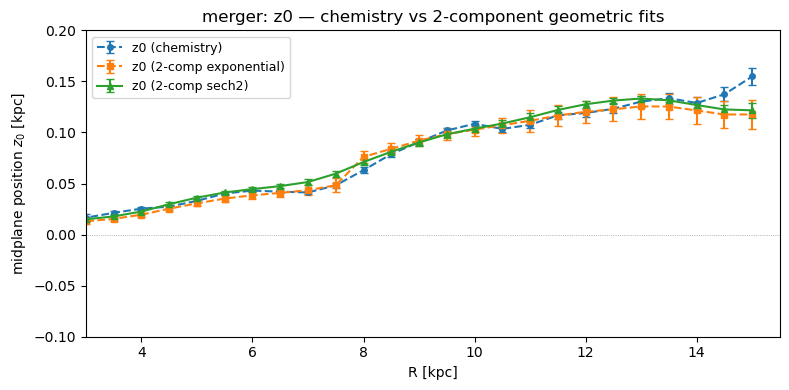

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
method_colors = {"chemistry": "C0", "exponential": "C1", "sech2": "C2"}
name = "merger"

ax.errorbar(R_centers_flare, z0_chem_summary[name]["z0_med"], yerr=z0_chem_summary[name]["z0_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="z0 (chemistry)")
ax.errorbar(R_centers_flare, z0_exp2_summary[name]["z0_med"], yerr=z0_exp2_summary[name]["z0_err"],
            fmt="s--", ms=4, capsize=3, color=method_colors["exponential"], label="z0 (2-comp exponential)")
ax.errorbar(R_centers_flare, z0_sech2_2_summary[name]["z0_med"], yerr=z0_sech2_2_summary[name]["z0_err"],
            fmt="^-", ms=4, capsize=3, color=method_colors["sech2"], label="z0 (2-comp sech2)")

ax.axhline(0, color='gray', lw=0.5, ls=':')
ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("midplane position $z_0$ [kpc]")
ax.set_title(f"{name}: z0 — chemistry vs 2-component geometric fits")
ax.set_xlim(3,15.5)
ax.set_ylim(-0.1,0.2)
plt.tight_layout()
plt.show()

In [34]:
age = df["age"].to_numpy().astype(float)
print("whole parquet:", np.nanmin(age), "-", np.nanmax(age))
# ~ -0.5 to 10  => already age
# ~ 12.7 to 23.5 => formation time; use age = 23.0068 - age
# age = 23.0068 - age

whole parquet: -7.919500433217763e-08 - 10.838766087165148
